# Sequence Analysis Toolkit

A small toolkit for basic DNA sequence analysis, applied to the human insulin (**INS**) mRNA.
It fetches the sequence from NCBI and computes GC content, GC skew, k-mer frequencies, the
reverse complement, open reading frames (ORFs), and the protein translation. Each from-scratch
function is cross-checked against Biopython.

**Data:** NCBI Entrez, RefSeq accession `NM_000207` (fetched live via the API).
**Language:** Python (Biopython, matplotlib).

In [1]:
%pip install biopython -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
from Bio import Entrez, SeqIO
from Bio.Seq import Seq
from collections import Counter
import matplotlib.pyplot as plt
import csv, os

os.makedirs('data', exist_ok=True)
os.makedirs('results', exist_ok=True)

## Fetch the sequence from NCBI

`efetch` returns the record as FASTA text; we parse it and cache a local copy so reruns
don't re-hit the API.

In [3]:
Entrez.email = 'yashraj.7156@gmail.com'   # NCBI requires an identifying email
ACCESSION = 'NM_000207'                   # human insulin (INS) mRNA

handle = Entrez.efetch(db='nucleotide', id=ACCESSION, rettype='fasta', retmode='text')
record = SeqIO.read(handle, 'fasta')
handle.close()
SeqIO.write(record, 'data/sequence.fasta', 'fasta')

seq = str(record.seq)
print(record.id, '-', record.description)
print('Length:', len(seq), 'bases')

NM_000207.3 - NM_000207.3 Homo sapiens insulin (INS), transcript variant 1, mRNA
Length: 465 bases


## Parse the FASTA

A minimal parser, checked against Biopython's `SeqIO`.

In [4]:
def parse_fasta(path):
    seqs = {}
    current_id = None
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line.startswith('>'):
                current_id = line[1:].split()[0]
                seqs[current_id] = ''
            else:
                seqs[current_id] += line
    return seqs

records = parse_fasta('data/sequence.fasta')
seq = records[list(records)[0]]

# cross-check against Biopython
for rec in SeqIO.parse('data/sequence.fasta', 'fasta'):
    assert len(rec.seq) == len(seq)
print('parsed', len(records), 'record(s); length', len(seq))

parsed 1 record(s); length 465


## GC content

Fraction of bases that are G or C.

In [5]:
def gc_content(seq):
    seq = seq.upper()
    if len(seq) == 0:
        return 0.0
    return (seq.count('G') + seq.count('C')) / len(seq)

print('GC content:', round(gc_content(seq), 3))
assert gc_content('GGGG') == 1.0 and gc_content('ATAT') == 0.0

GC content: 0.639


## GC skew

(G − C) / (G + C) measured over non-overlapping windows.

In [6]:
def gc_skew(seq, window=50):
    seq = seq.upper()
    skews = []
    for i in range(0, len(seq) - window + 1, window):
        w = seq[i:i+window]
        g, c = w.count('G'), w.count('C')
        skews.append((g - c) / (g + c) if (g + c) else 0)
    return skews

skews = gc_skew(seq, window=50)
print(len(skews), 'windows')

9 windows


## k-mer frequencies

Counts of every substring of length *k*.

In [7]:
def kmer_counts(seq, k=3):
    seq = seq.upper()
    return Counter(seq[i:i+k] for i in range(len(seq) - k + 1))

counts = kmer_counts(seq, k=3)
print('distinct 3-mers:', len(counts))
print('top 5:', counts.most_common(5))

distinct 3-mers: 60
top 5: [('CTG', 24), ('CCT', 22), ('GCC', 19), ('CAG', 19), ('CCC', 18)]


## Reverse complement

Complement each base (A↔T, G↔C) and reverse. Applying it twice must return the original.

In [8]:
def reverse_complement(seq):
    seq = seq.upper()
    complement = {'A':'T', 'T':'A', 'G':'C', 'C':'G', 'N':'N'}
    return ''.join(complement[base] for base in seq)[::-1]

print('ATGC ->', reverse_complement('ATGC'))
assert reverse_complement(reverse_complement(seq)) == seq   # involution check

ATGC -> GCAT


## Open reading frames

Scan the three forward frames for ATG ... in-frame stop.

In [9]:
STOPS = {'TAA', 'TAG', 'TGA'}

def find_orfs(seq, min_len=60):
    seq = seq.upper()
    orfs = []
    for frame in range(3):
        i = frame
        while i < len(seq) - 2:
            if seq[i:i+3] == 'ATG':
                j = i
                while j < len(seq) - 2:
                    if seq[j:j+3] in STOPS:
                        orf = seq[i:j+3]
                        if len(orf) >= min_len:
                            orfs.append(orf)
                        i = j
                        break
                    j += 3
            i += 3
    return orfs

orfs = find_orfs(seq, min_len=60)
print('ORFs found:', len(orfs))
for o in orfs:
    print(len(o), 'bp')

ORFs found: 1
333 bp


## Translation

Read the longest ORF codon by codon; cross-check against Biopython.

In [10]:
CODON_TABLE = {
    'TTT':'F','TTC':'F','TTA':'L','TTG':'L','CTT':'L','CTC':'L','CTA':'L','CTG':'L',
    'ATT':'I','ATC':'I','ATA':'I','ATG':'M','GTT':'V','GTC':'V','GTA':'V','GTG':'V',
    'TCT':'S','TCC':'S','TCA':'S','TCG':'S','CCT':'P','CCC':'P','CCA':'P','CCG':'P',
    'ACT':'T','ACC':'T','ACA':'T','ACG':'T','GCT':'A','GCC':'A','GCA':'A','GCG':'A',
    'TAT':'Y','TAC':'Y','TAA':'*','TAG':'*','CAT':'H','CAC':'H','CAA':'Q','CAG':'Q',
    'AAT':'N','AAC':'N','AAA':'K','AAG':'K','GAT':'D','GAC':'D','GAA':'E','GAG':'E',
    'TGT':'C','TGC':'C','TGA':'*','TGG':'W','CGT':'R','CGC':'R','CGA':'R','CGG':'R',
    'AGT':'S','AGC':'S','AGA':'R','AGG':'R','GGT':'G','GGC':'G','GGA':'G','GGG':'G',
}

def translate(dna):
    dna = dna.upper()
    protein = ''
    for i in range(0, len(dna) - 2, 3):
        protein += CODON_TABLE.get(dna[i:i+3], 'X')
    return protein

longest = max(orfs, key=len) if orfs else seq
protein = translate(longest)
print(protein)
assert protein == str(Seq(longest).translate())   # matches Biopython

MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN*


## Summary table

Write the per-sequence results to `results/summary.csv`.

In [11]:
rows = []
for rid, s in records.items():
    orfs_s = find_orfs(s, min_len=60)
    rows.append([
        rid,
        len(s),
        round(gc_content(s), 4),
        len(orfs_s),
        max((len(o) for o in orfs_s), default=0),
        kmer_counts(s, 3).most_common(1)[0][0],
    ])

with open('results/summary.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['seq_id', 'length', 'gc_content', 'n_orfs', 'longest_orf_bp', 'top_3mer'])
    w.writerows(rows)

print(open('results/summary.csv').read())

seq_id,length,gc_content,n_orfs,longest_orf_bp,top_3mer
NM_000207.3,465,0.6387,1,333,CTG



## Figure: GC skew

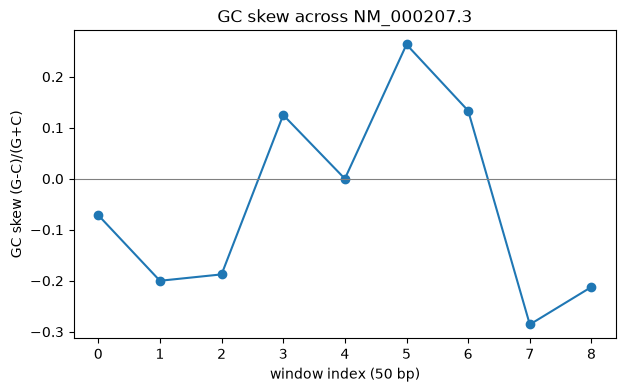

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(skews, marker='o')
plt.axhline(0, color='grey', linewidth=0.8)
plt.xlabel('window index (50 bp)')
plt.ylabel('GC skew (G-C)/(G+C)')
plt.title(f'GC skew across {record.id}')
plt.savefig('results/gc_skew.png', dpi=300, bbox_inches='tight')
plt.show()

## Results and interpretation

- The insulin mRNA (465 nt) has a GC content of ~0.64 — GC-rich, as expected for a human coding transcript.
- A single forward-strand ORF of **333 bp** is recovered. Its translation (`MALWMRLLPLL...ENYCN*`, 110 aa)
  is **preproinsulin** — signal peptide, B-chain, C-peptide and A-chain — and matches Biopython's translation exactly.
- The reverse-complement passes its involution check (`revcomp(revcomp(seq)) == seq`).

**Limitations.** ORF detection here covers the three *forward* frames only (no reverse strand), and uses a
single sequence, so nothing generalizes. GC skew is a genome/replication-origin scale signal, so on a 465 nt
mRNA it is shown for completeness rather than biological meaning.